In [1]:
%load_ext autoreload
%autoreload 2
import os
import sys
from matplotlib import pyplot as plt

# the code is under /home, the data and inference output under /scratch (as in post_generals_analysis)
CODE_DIR = "/home/abronner/TimeSeriesNetworkInference"
PARENT_DIR = "/scratch/gpfs/MONA/abronner/TimeSeriesNetworkInference"
sys.path.insert(0, CODE_DIR)
from validation import paper_figures_analysis as pfa

INFERENCE_DIR = os.path.join(PARENT_DIR, "inferred_models", "generated")
DATA_DIR = os.path.join(PARENT_DIR, "data", "generated")
FIGURES_DIR = os.path.join(PARENT_DIR, "validation", "paper_figures")

# hit-rate on varying nodes is drawn when some method's mean differs from its all-nodes mean by at least this
VARYING_GAP_THRESHOLD = 0.1
# write the varying-node and edge-sign score files older runs lack (False: draw only what is on disk)
COMPUTE_MISSING_SCORES = True

## Experiments

`dir` is the experiment under `inferred_models/generated` (its data under `data/generated`); `sweep` the parameter drawn on the x axis, with its label; `show_varying` forces the varying-nodes panel on (True) or off (False) instead of deciding by `VARYING_GAP_THRESHOLD`.

In [2]:
EXPERIMENTS = {
    "feedforward_noisy":      dict(dir="classic_toy_models_3rd", title="Feedforward Circuits, Noisy PKN"),
    "feedforward_undirected": dict(dir="classic_toy_models_nofn_3rd", title="Feedforward Circuits, Undirected PKN"),
    "feedback_noisy":         dict(dir="dynamic_toy_models_3rd", title="Feedback Circuits, Noisy PKN"),
    "feedback_undirected":    dict(dir="dynamic_toy_models_nofn_3rd", title="Feedback Circuits, Undirected PKN"),
    "random_nk":              dict(dir="random_nk_30_3rd_nofn", title="Random N-K Networks, Undirected PKN",
                                   sweep="K", x_label="K"),
    "random_scale_free":      dict(dir="random_scale_free_30_3rd_nofn",
                                   title="Random Scale-Free Networks, Undirected PKN",
                                   sweep="size", x_label="Network Size"),
    "random_regulatory_topology": dict(dir="random_regulatory_topology_networks_nofn",
                                       title="Random Regulatory Topology Networks, Undirected PKN",
                                       sweep="size", x_label="Network Size"),
    "regulondb_random_threshold": dict(dir="regulondb_random_threshold_models_nofn",
                                       title="RegulonDB Random Threshold Models, Undirected PKN"),
    "regulondb_strict_regulators_random_threshold": dict(
        dir="regulondb_strict_regulators_random_threshold_models_nofn",
        title="RegulonDB Strict Regulators Random Threshold Models, Undirected PKN"),
}

data = {}
for name, exp in EXPERIMENTS.items():
    exp_dir = os.path.join(INFERENCE_DIR, exp["dir"])
    try:
        if COMPUTE_MISSING_SCORES:
            pfa.compute_missing_scores(exp_dir, os.path.join(DATA_DIR, exp["dir"]))
        data[name] = pfa.load_experiment(exp_dir, sweep=exp.get("sweep"))
    except Exception as e:
        print(f"Could not load {exp['dir']}: {e}")


def draw(name):
    """Draws and saves (FIGURES_DIR/<name>__accuracy, __time, __failed) one experiment's three figures."""
    exp = EXPERIMENTS[name]
    figures = pfa.experiment_figures(data[name], exp["title"], exp.get("x_label"), exp.get("show_varying"),
                                     VARYING_GAP_THRESHOLD)
    for fig, kind in zip(figures, ("accuracy", "time", "failed")):
        pfa.save_figure(fig, FIGURES_DIR, f"{name}__{kind}")
    plt.show()

Computing missing scores for /scratch/gpfs/MONA/abronner/TimeSeriesNetworkInference/inferred_models/generated/classic_toy_models_3rd
    200/1960 models checked
    400/1960 models checked
    600/1960 models checked
    800/1960 models checked
    1000/1960 models checked
    1200/1960 models checked
    1400/1960 models checked
    1600/1960 models checked
    1800/1960 models checked
  1960 model(s): wrote 0 varying-node and 0 edge-sign score file(s)
Loading /scratch/gpfs/MONA/abronner/TimeSeriesNetworkInference/inferred_models/generated/classic_toy_models_3rd
Computing missing scores for /scratch/gpfs/MONA/abronner/TimeSeriesNetworkInference/inferred_models/generated/classic_toy_models_nofn_3rd
    200/1960 models checked
    400/1960 models checked
    600/1960 models checked
    800/1960 models checked
    1000/1960 models checked
    1200/1960 models checked
    1400/1960 models checked
    1600/1960 models checked
    1800/1960 models checked
  1960 model(s): wrote 0 varying-no

## Feedforward Circuits

  largest all-nodes vs varying-nodes hit-rate gap: 0.238 -> varying-nodes panel drawn


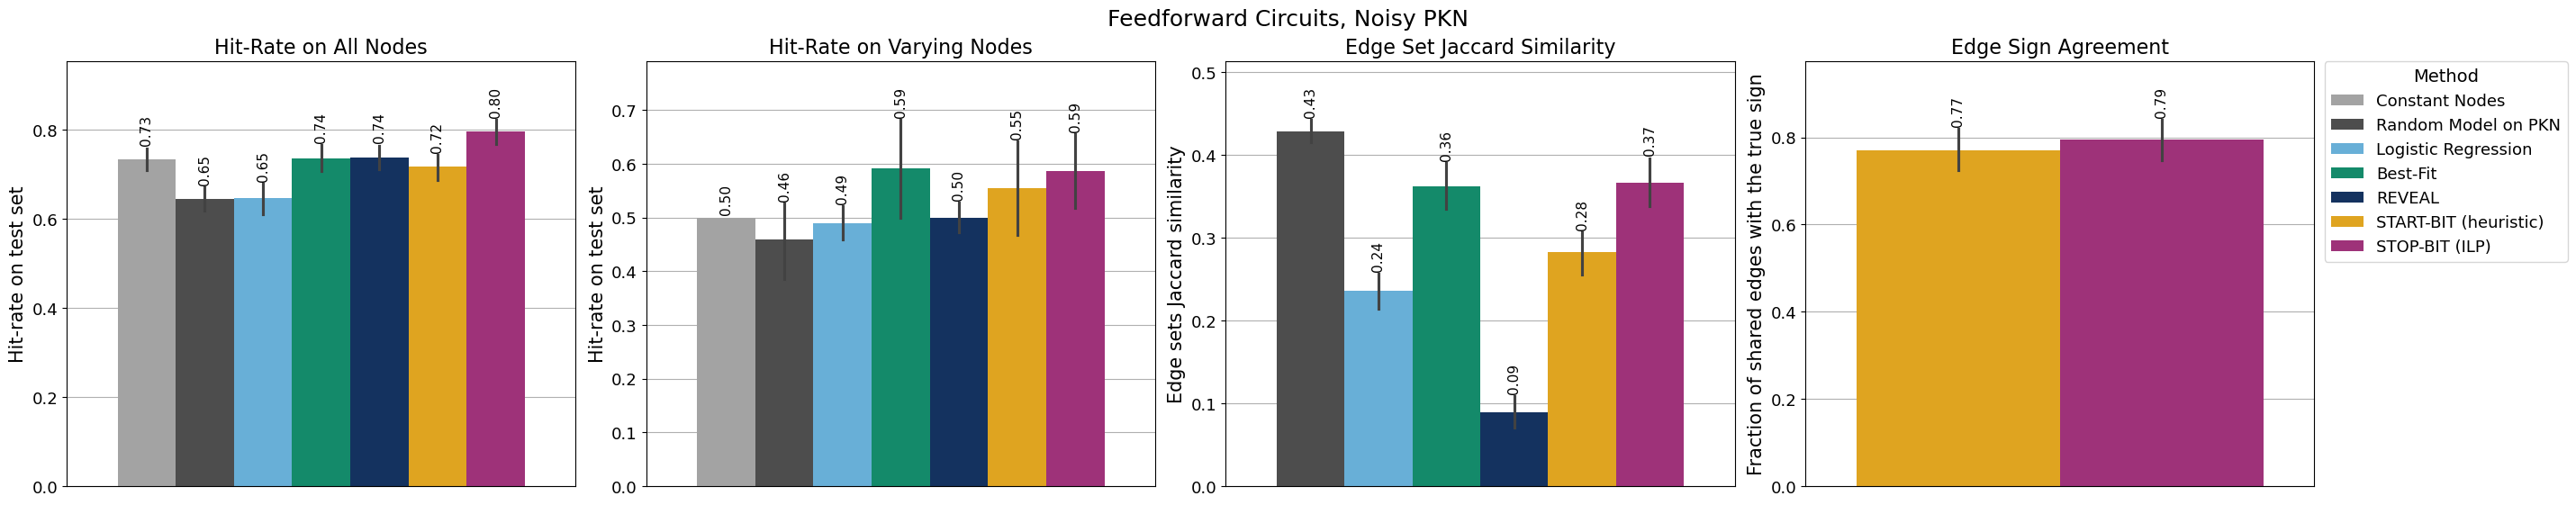

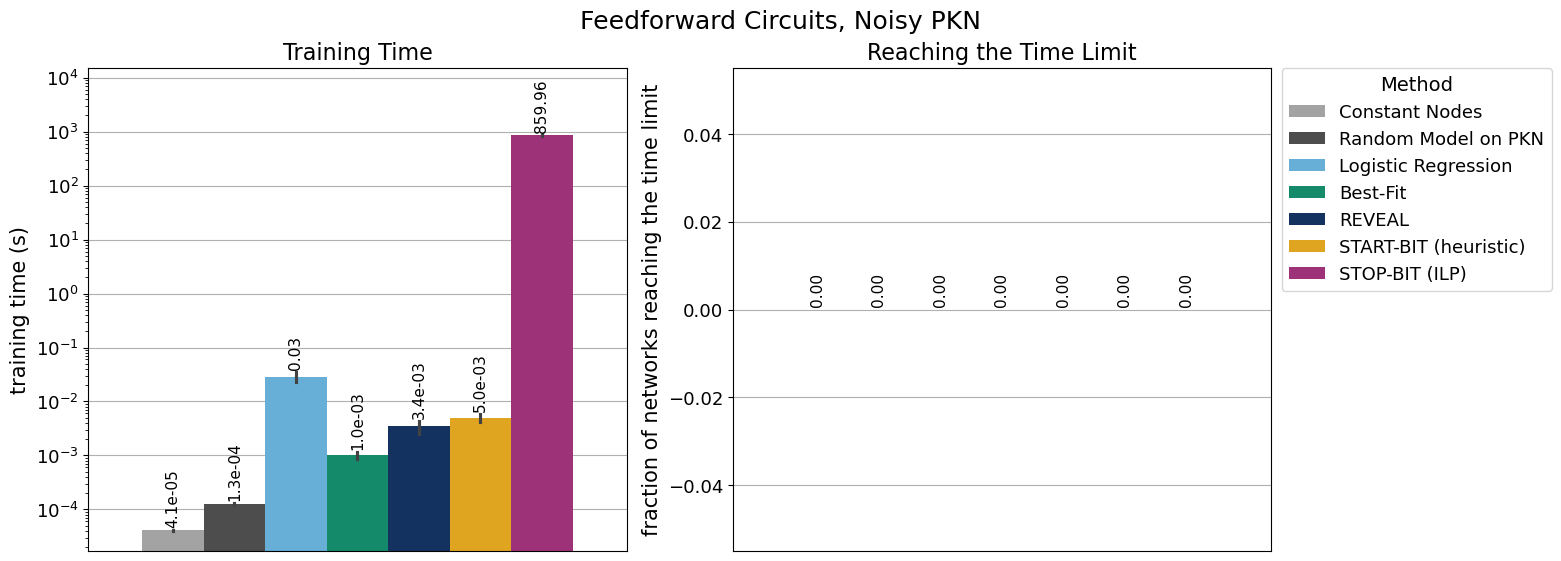

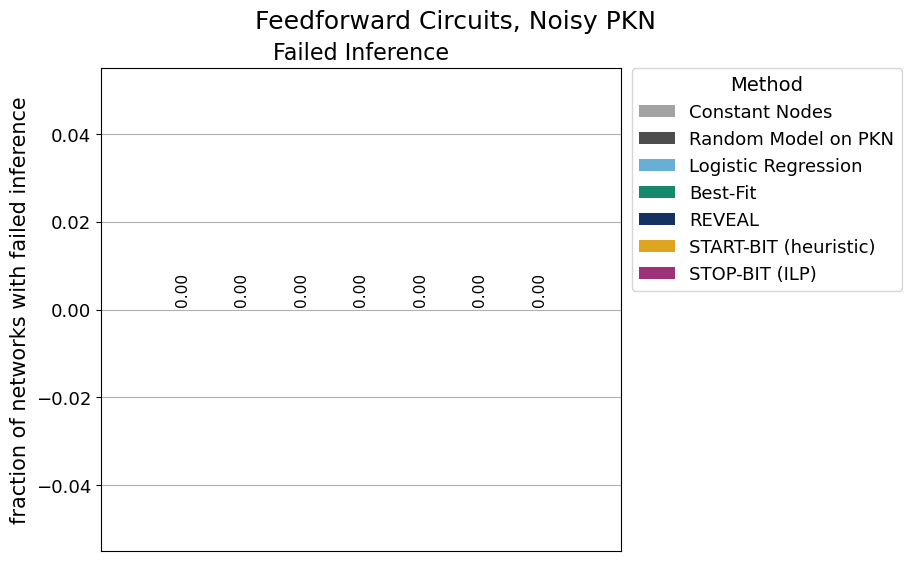

In [3]:
draw("feedforward_noisy")

  largest all-nodes vs varying-nodes hit-rate gap: 0.228 -> varying-nodes panel drawn


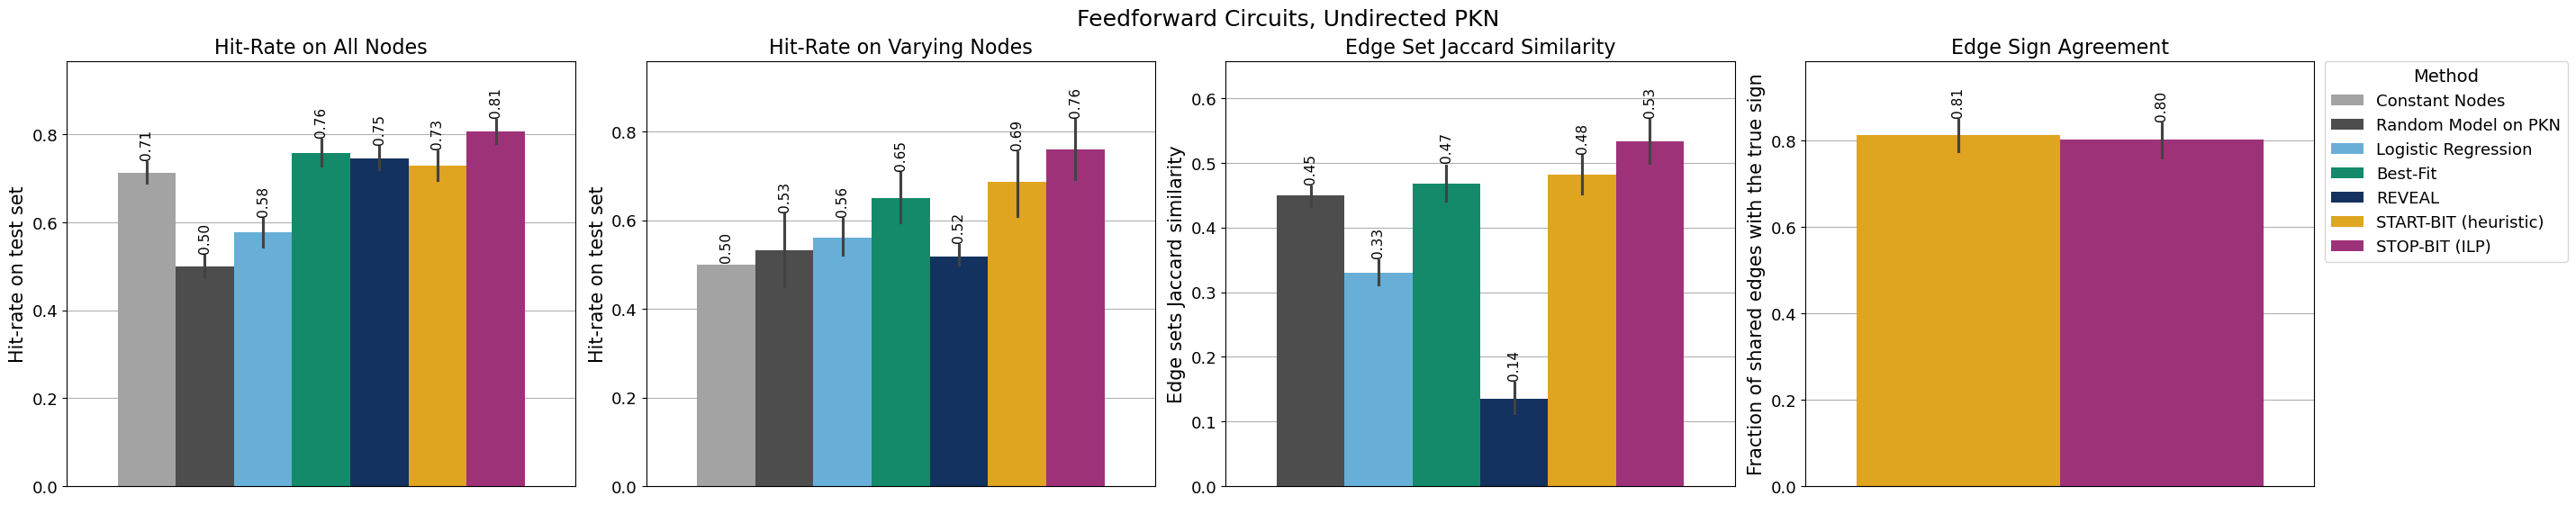

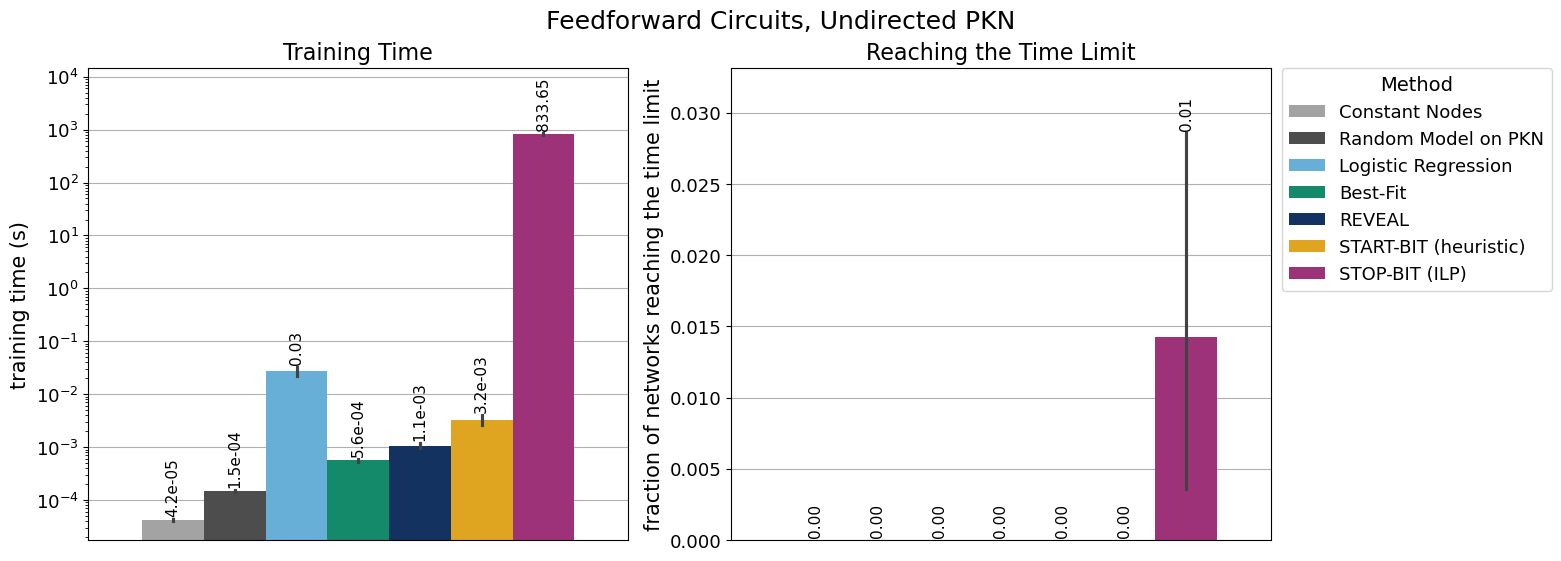

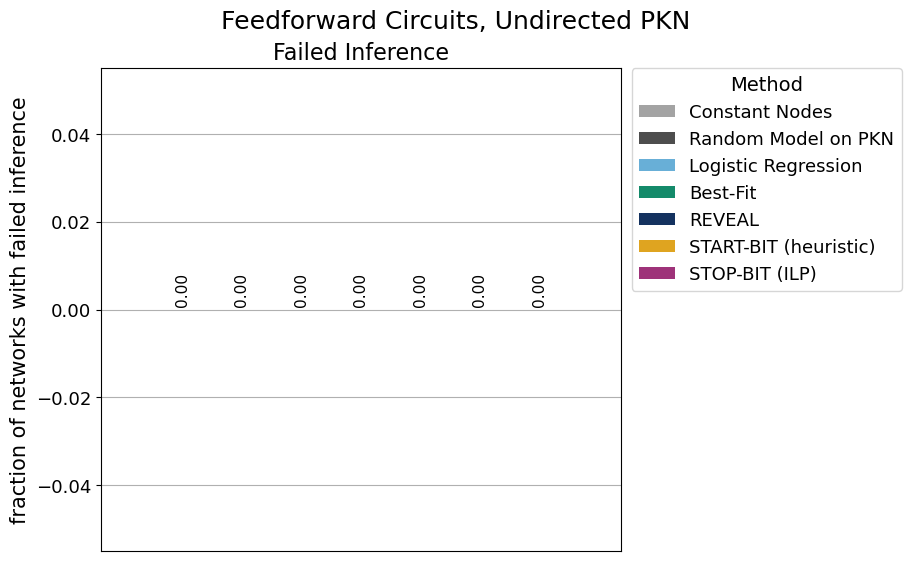

In [4]:
draw("feedforward_undirected")

## Feedback Circuits

  largest all-nodes vs varying-nodes hit-rate gap: 0.029 -> varying-nodes panel left out


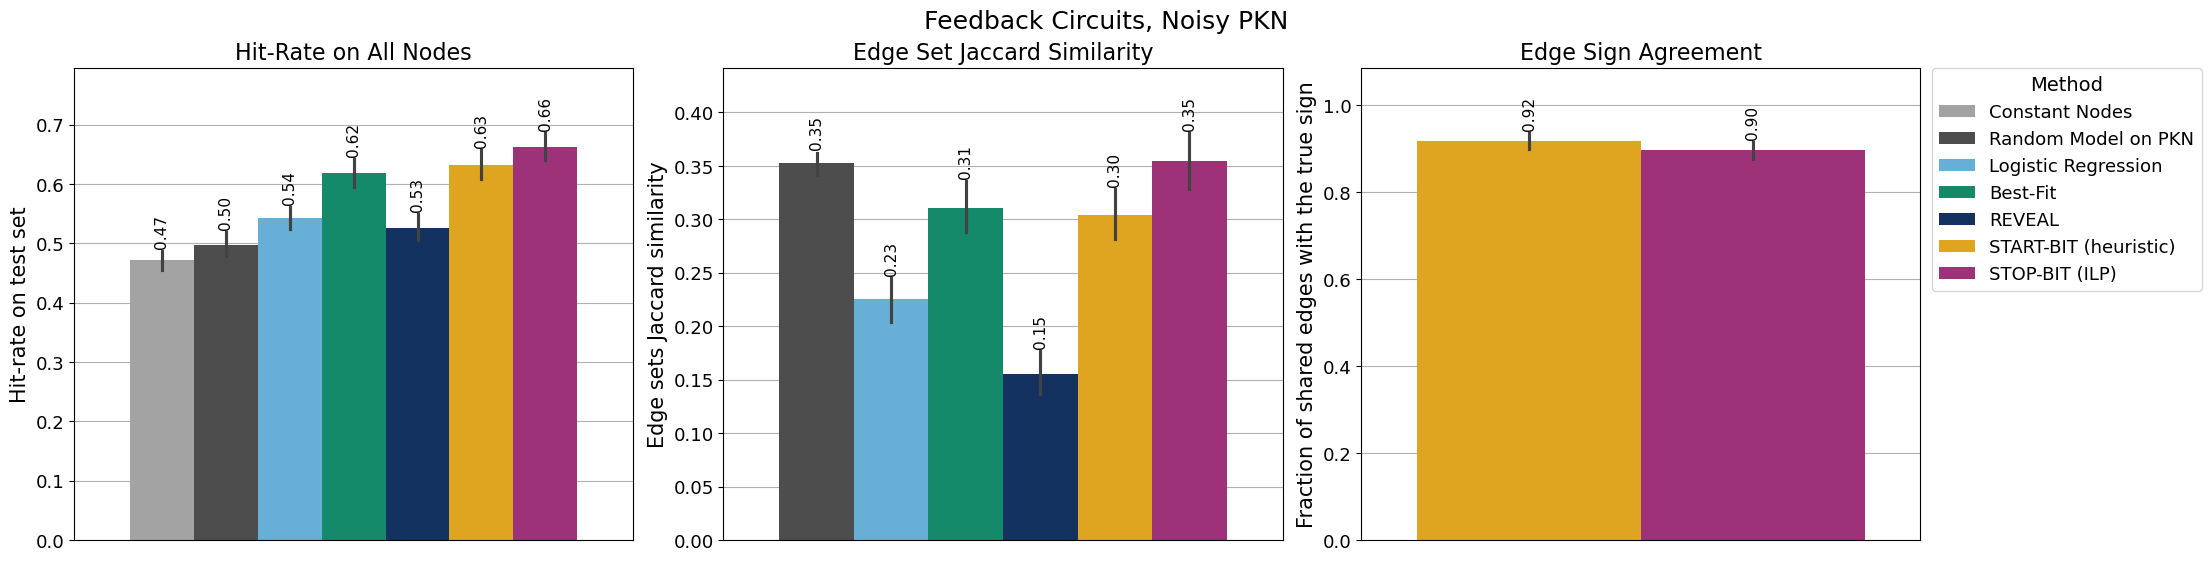

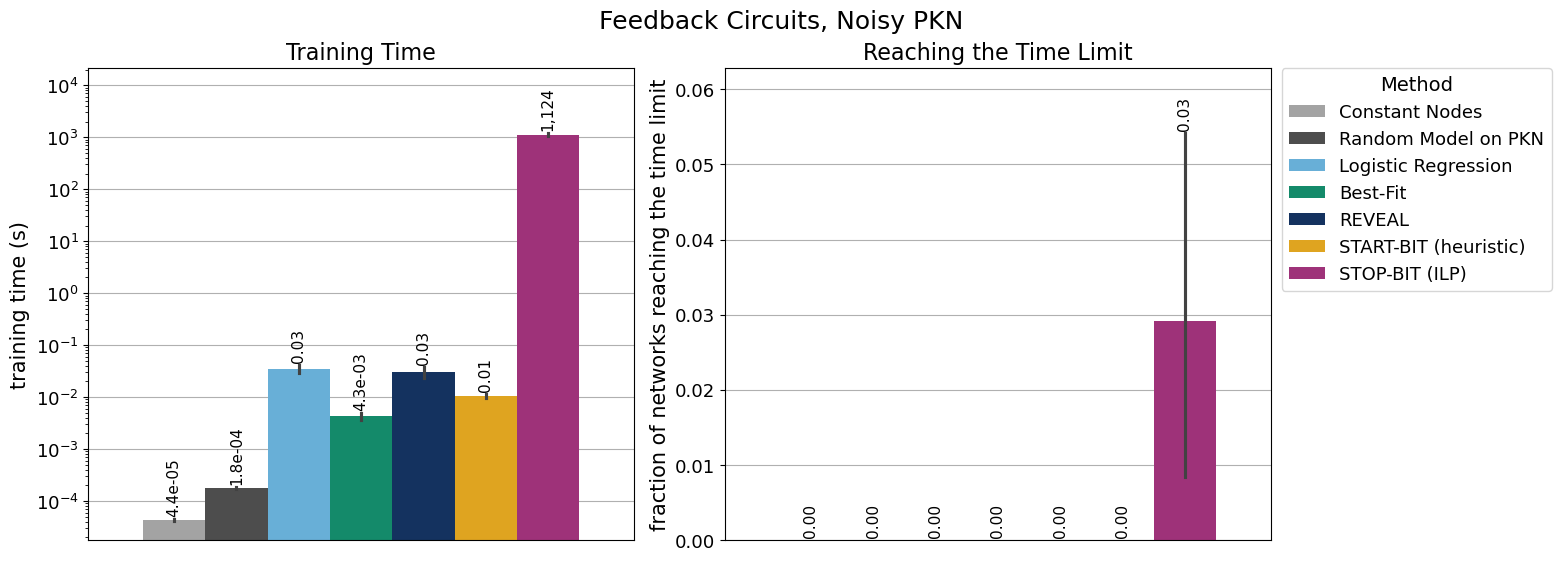

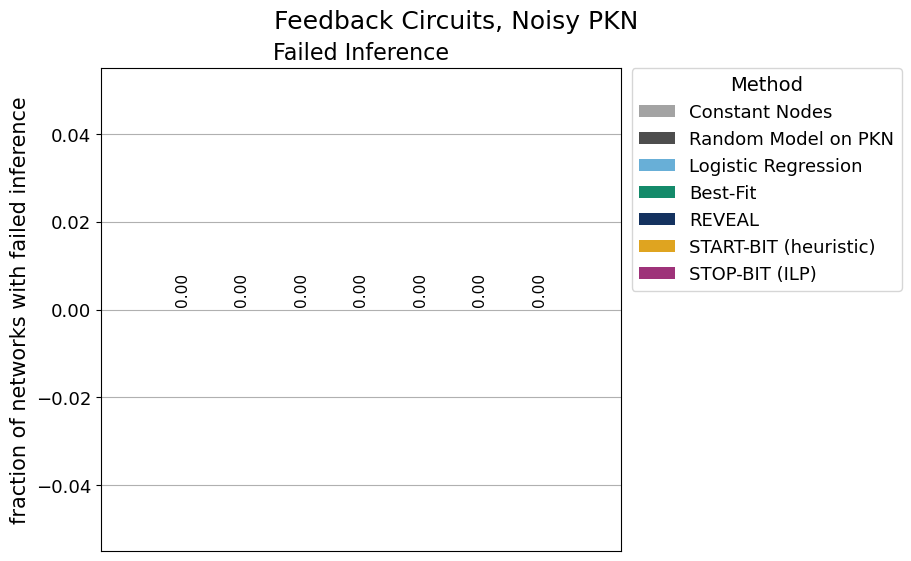

In [5]:
draw("feedback_noisy")

  largest all-nodes vs varying-nodes hit-rate gap: 0.033 -> varying-nodes panel left out


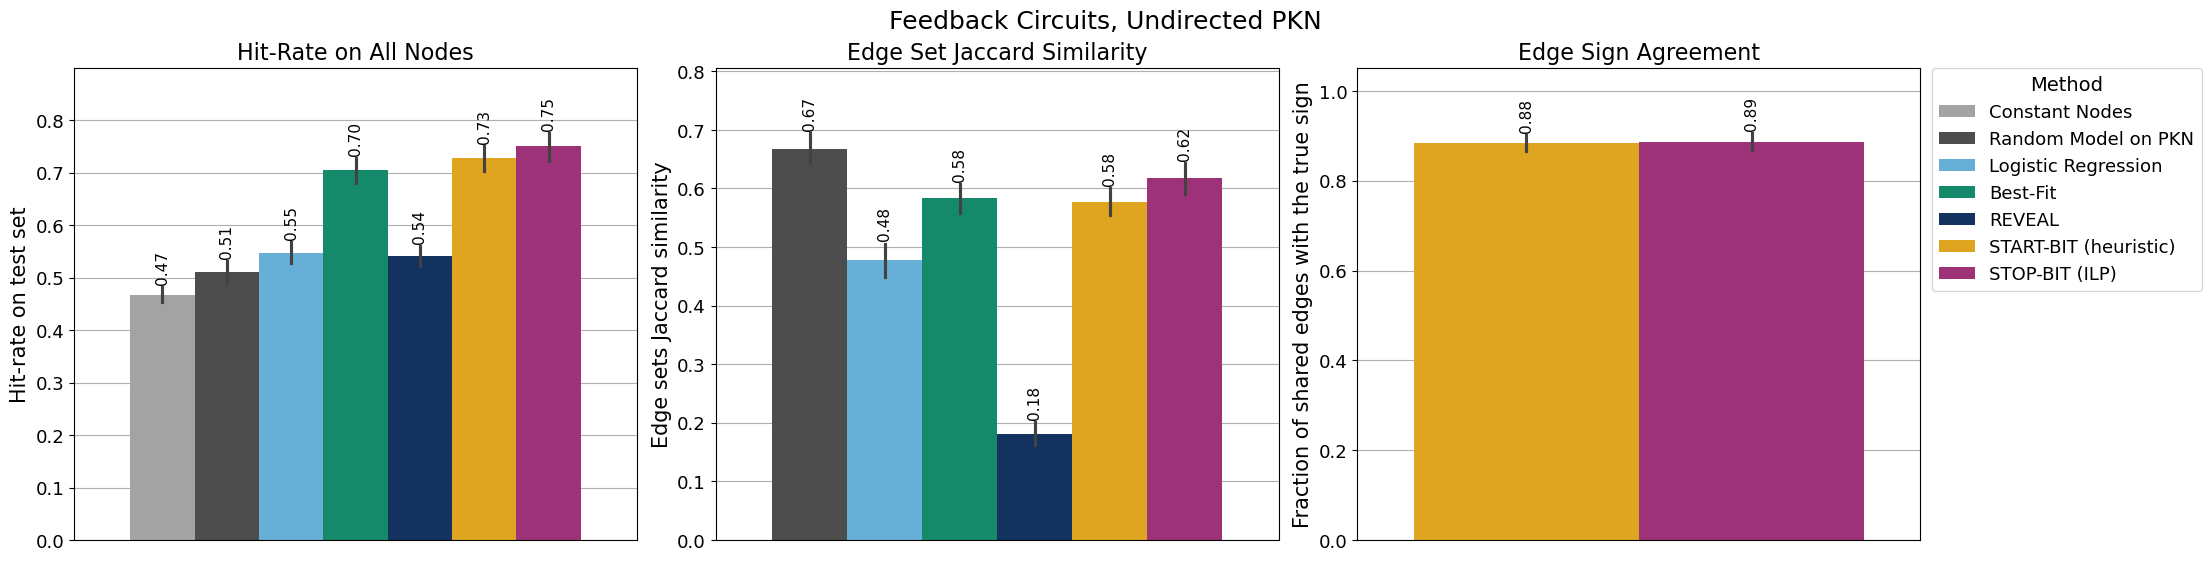

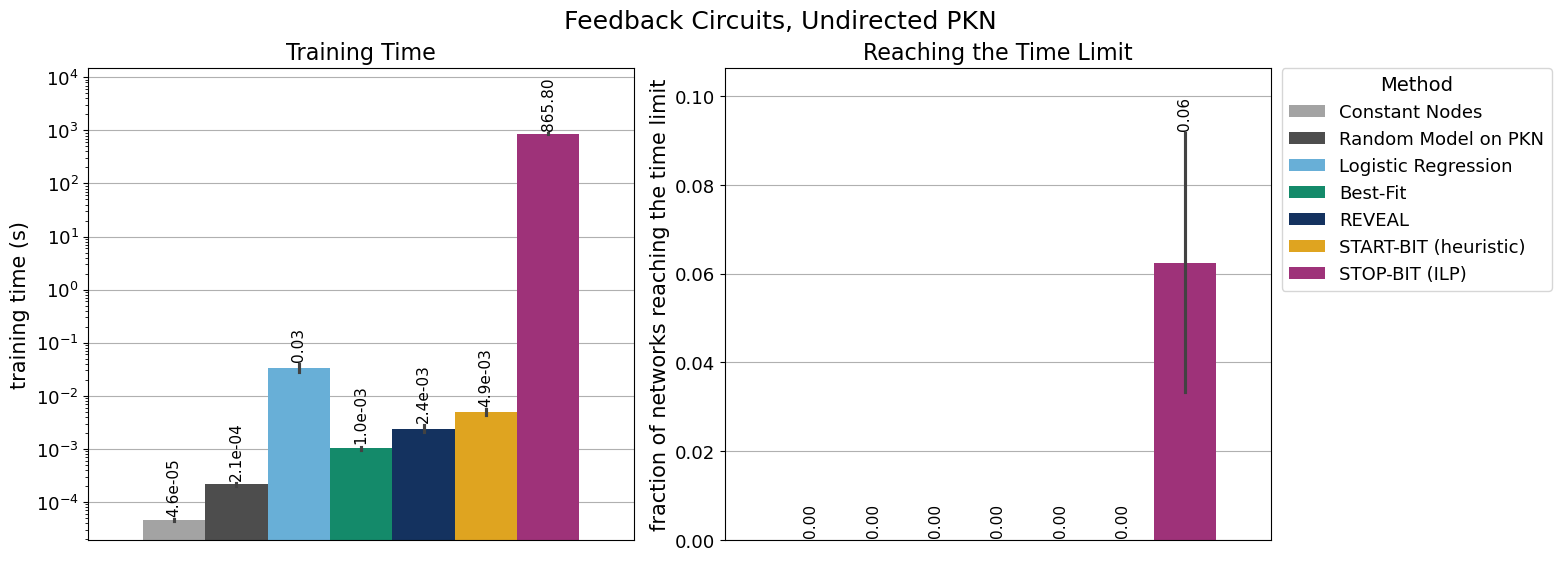

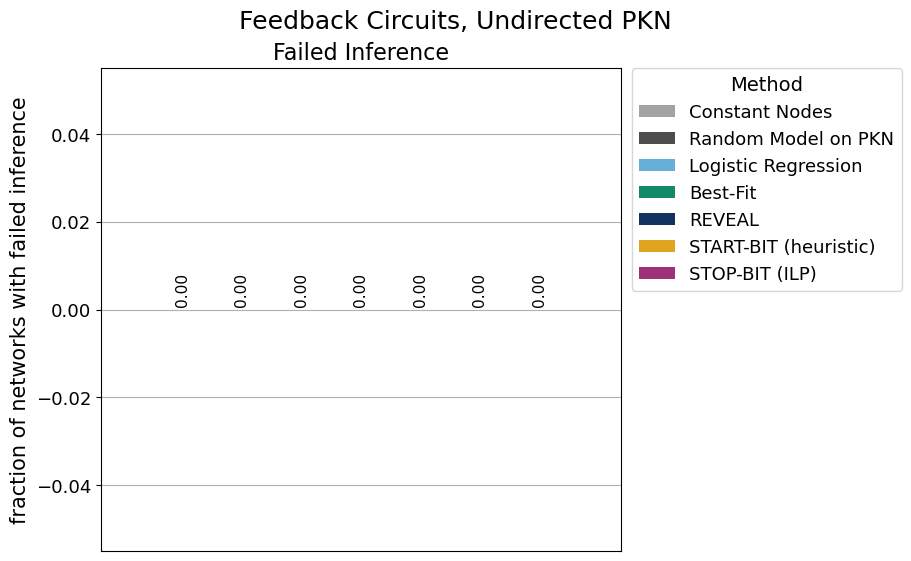

In [6]:
draw("feedback_undirected")

## Running Time, Feedforward and Feedback Circuits

In [7]:
PKN_LABELS = {"noisy": "Noisy PKN", "undirected": "Undirected PKN"}
circuit_panels = {circuit_title: {label: data[f"{circuit}_{pkn}"] for pkn, label in PKN_LABELS.items()
                                  if f"{circuit}_{pkn}" in data}
                  for circuit, circuit_title in (("feedforward", "Feedforward Circuits"),
                                                 ("feedback", "Feedback Circuits"))}
fig = pfa.metric_subplots_figure(circuit_panels, "timing", "Training Time")
pfa.save_figure(fig, FIGURES_DIR, "circuits__time")
plt.show()

AttributeError: module 'validation.paper_figures_analysis' has no attribute 'metric_subplots_figure'

## Random N-K Networks

In [ ]:
draw("random_nk")

## Random Scale-Free Networks

In [ ]:
draw("random_scale_free")

## Random Regulatory Topology Networks

In [ ]:
draw("random_regulatory_topology")

## RegulonDB Random Threshold Models

In [ ]:
draw("regulondb_random_threshold")

In [ ]:
draw("regulondb_strict_regulators_random_threshold")

## Running Time, All Experiments

`TIMING_PANELS` maps each panel's title to its bar groups (`{group label: experiment}`); a swept experiment takes a panel of its own, drawn as lines.

In [ ]:
TIMING_PANELS = {
    "Feedforward Circuits": {"Noisy PKN": "feedforward_noisy", "Undirected PKN": "feedforward_undirected"},
    "Feedback Circuits": {"Noisy PKN": "feedback_noisy", "Undirected PKN": "feedback_undirected"},
    "Random N-K Networks": {"Undirected PKN": "random_nk"},
    "Random Scale-Free Networks": {"Undirected PKN": "random_scale_free"},
    "Random Regulatory Topology Networks": {"Undirected PKN": "random_regulatory_topology"},
    "RegulonDB Random Threshold Models": {"All Regulators": "regulondb_random_threshold",
                                          "Strict Regulators": "regulondb_strict_regulators_random_threshold"},
}
TIMING_NCOLS = 3

panels = {title: {label: data[name] for label, name in groups.items() if name in data}
          for title, groups in TIMING_PANELS.items()}
x_labels = {title: EXPERIMENTS[name].get("x_label") for title, groups in TIMING_PANELS.items()
            for name in groups.values()}
fig = pfa.metric_subplots_figure(panels, "timing", "Training Time", x_labels=x_labels, ncols=TIMING_NCOLS)
pfa.save_figure(fig, FIGURES_DIR, "all_experiments__time")
plt.show()